In [6]:
# EXPERIMENT: Comparative Analysis of Bagging and Boosting Ensemble Methods for Heart Disease Prediction

# Objective:
# Implement and compare Bagging and Boosting ensemble learning techniques on the Heart Disease dataset. Evaluate their performance using classification metrics and visualize the results using appropriate plots.

# Dataset:
# Heart Disease Dataset (UCI/Kaggle)

# Tasks:

# 1. Load the Heart Disease dataset and perform exploratory data analysis (EDA).
#    - Display dataset information and summary statistics.
#    - Check for missing values and handle them appropriately.
#    - Identify feature variables and target variable.

# 2. Preprocess the dataset.
#    - Handle missing values.
#    - Encode categorical attributes if required.
#    - Separate the data into features (X) and target (y).
#    - Split the data into training and testing sets.

# 3. Implement Bagging.
#    - Use Decision Tree as the base estimator.
#    - Train a Bagging Classifier on the training dataset.
#    - Predict the target values for the test dataset.

# 4. Implement Boosting.
#    - Use AdaBoost with Decision Tree as the base estimator.
#    - Train the model on the training dataset.
#    - Predict the target values for the test dataset.

# 5. Evaluate both models using:
#    - Accuracy
#    - Precision
#    - Recall
#    - F1-Score

# 6. Compare the performance of Bagging and AdaBoost using a tabular representation.

# Plots to Include:

# 1. Target Class Distribution
#    - Bar plot showing the number of patients with and without heart disease.

# 3. Confusion Matrix for Bagging Classifier
#    - Visualize True Positives, True Negatives, False Positives, and False Negatives.

# 4. Confusion Matrix for AdaBoost Classifier
#    - Compare classification errors with Bagging.

# 5. ROC Curve Comparison
#    - Plot ROC curves for both models on the same graph.
#    - Include AUC scores and the random baseline.

# 6. Model Performance Comparison
#    - Create a grouped bar chart comparing:
#      • Accuracy
#      • Precision
#      • Recall
#      • F1-Score
#    - Compare Bagging and AdaBoost side by side.

# 7. Feature Importance Plot
#    - Display the importance of features obtained from the AdaBoost model.
#    - Identify the most influential attributes in heart disease prediction.

In [36]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,ConfusionMatrixDisplay,confusion_matrix,RocCurveDisplay
from sklearn.ensemble import BaggingClassifier , AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split

In [8]:
df = pd.read_csv(r".\heart.csv")
df.head(10)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0
5,58,0,0,100,248,0,0,122,0,1.0,1,0,2,1
6,58,1,0,114,318,0,2,140,0,4.4,0,3,1,0
7,55,1,0,160,289,0,0,145,1,0.8,1,1,3,0
8,46,1,0,120,249,0,0,144,0,0.8,2,0,3,0
9,54,1,0,122,286,0,0,116,1,3.2,1,2,2,0


In [9]:
x = df.drop("target",axis = 1)
y = df['target']

In [10]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state =42)

In [11]:
bag = BaggingClassifier(estimator = DecisionTreeClassifier(),n_estimators = 50,random_state = 42)
bag.fit(x_train,y_train)

,"estimator estimator: object, default=NoneThe base estimator to fit on random subsets of the dataset.If None, then the base estimator is a:class:`~sklearn.tree.DecisionTreeClassifier`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",DecisionTreeClassifier()
,"n_estimators n_estimators: int, default=10The number of base estimators in the ensemble.",50
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random resampling of the original dataset(sample wise and feature wise).If the base estimator accepts a `random_state` attribute, a differentseed is generated for each instance in the ensemble.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"max_samples max_samples: int or float, default=NoneThe number of samples to draw from X to train each base estimator (withreplacement by default, see `bootstrap` for more details).- If None, then draw `X.shape[0]` samples irrespective of `sample_weight`.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` unweighted samples or `max_samples * sample_weight.sum()` weighted samples.",None
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator (without replacement by default, see `bootstrap_features` for moredetails).- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.",1.0
,"bootstrap bootstrap: bool, default=TrueWhether samples are drawn with replacement. If False, sampling withoutreplacement is performed. If fitting with `sample_weight`, it isstrongly recommended to choose True, as only drawing with replacementwill ensure the expected frequency semantics of `sample_weight`.",True
,"bootstrap_features bootstrap_features: bool, default=FalseWhether features are drawn with replacement.",False
,"oob_score oob_score: bool, default=FalseWhether to use out-of-bag samples to estimatethe generalization error. Only available if bootstrap=True.",False
,"warm_start warm_start: bool, default=FalseWhen set to True, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fita whole new ensemble. See :term:`the Glossary <warm_start>`... versionadded:: 0.17 *warm_start* constructor parameter.",False
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for both :meth:`fit` and:meth:`predict`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"verbose verbose: int, default=0Controls the verbosity when fitting and predicting.",0


In [12]:
ada = AdaBoostClassifier(estimator = DecisionTreeClassifier(max_depth = 1),n_estimators = 50,random_state = 42)
ada.fit(x_train,y_train)

,"estimator estimator: object, default=NoneThe base estimator from which the boosted ensemble is built.Support for sample weighting is required, as well as proper``classes_`` and ``n_classes_`` attributes. If ``None``, thenthe base estimator is :class:`~sklearn.tree.DecisionTreeClassifier`initialized with `max_depth=1`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",DecisionTreeC...r(max_depth=1)
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given at each `estimator` at eachboosting iteration.Thus, it is only used when `estimator` exposes a `random_state`.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"n_estimators n_estimators: int, default=50The maximum number of estimators at which boosting is terminated.In case of perfect fit, the learning procedure is stopped early.Values must be in the range `[1, inf)`.",50
,"learning_rate learning_rate: float, default=1.0Weight applied to each classifier at each boosting iteration. A higherlearning rate increases the contribution of each classifier. There isa trade-off between the `learning_rate` and `n_estimators` parameters.Values must be in the range `(0.0, inf)`.",1.0
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels.","ndarray[int64](2,)","[0,1]"
estimator_ estimator_: estimatorThe base estimator from which the ensemble is grown... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,DecisionTreeClassifier,DecisionTreeC...r(max_depth=1)
estimator_errors_ estimator_errors_: ndarray of floatsClassification error for each estimator in the boostedensemble.,"ndarray[float64](50,)","[0.24,0.26,0.29,...,0.48,0.47,0.48]"
estimator_weights_ estimator_weights_: ndarray of floatsWeights for each estimator in the boosted ensemble.,"ndarray[float64](50,)","[1.16,1.05,0.91,...,0.07,0.12,0.06]"
estimators_ estimators_: list of classifiersThe collection of fitted sub-estimators.,list,"[DecisionTreeC...te=1608637542), DecisionTreeC...te=1273642419), DecisionTreeC...te=1935803228), DecisionTreeC...ate=787846414), ...]"
"feature_importances_ feature_importances_: ndarray of shape (n_features,)The impurity-based feature importances if supported by the``estimator`` (when based on decision trees).Warning: impurity-based feature importances can be misleading forhigh cardinality features (many unique values). See:func:`sklearn.inspection.permutation_importance` as an alternative.","ndarray[float64](13,)","[0.1 ,0.06,0.08,...,0.03,0.12,0.06]"


In [13]:
models = {"Bagging Classifier":bag,"Boosting Classifier":ada}
results = []
for name,model in models.items():
    pred = model.predict(x_test)
    results.append([(name),
    (accuracy_score(y_test,pred)),
    (precision_score(y_test,pred,zero_division = 0)),
    (recall_score(y_test,pred,zero_division = 0)),
    (f1_score(y_test,pred,zero_division = 0))])
comparison = pd.DataFrame(results,columns = ["Model","Accuracy","Precision","Recall","F1"])

comparison

,Model,Accuracy,Precision,Recall,F1
0,Bagging Classifier,0.985366,1.000000,0.970874,0.985222
1,Boosting Classifier,0.814634,0.792793,0.854369,0.822430


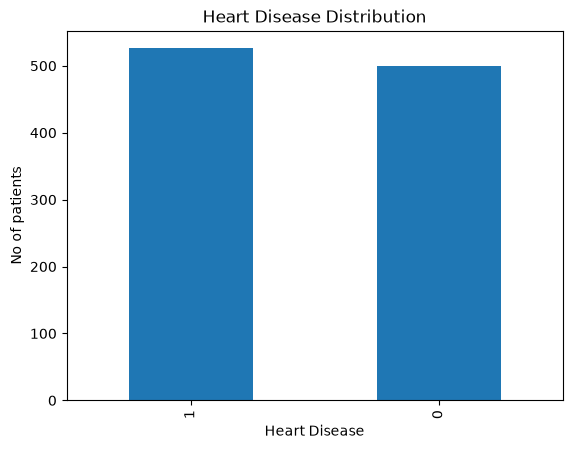

In [14]:
# BAR PLOT
y.value_counts().plot(kind = 'bar')
plt.xlabel("Heart Disease")
plt.ylabel("No of patients")
plt.title("Heart Disease Distribution")
plt.show()


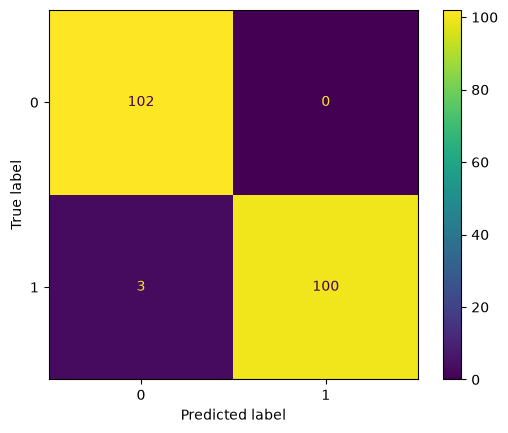

In [17]:
# Confusion Matrices
bag_pred= bag.predict(x_test)
cm1 = confusion_matrix(y_test,bag_pred)
cm2 = confusion_matrix(y_test,pred)
ConfusionMatrixDisplay(confusion_matrix = cm1).plot()
plt.show()

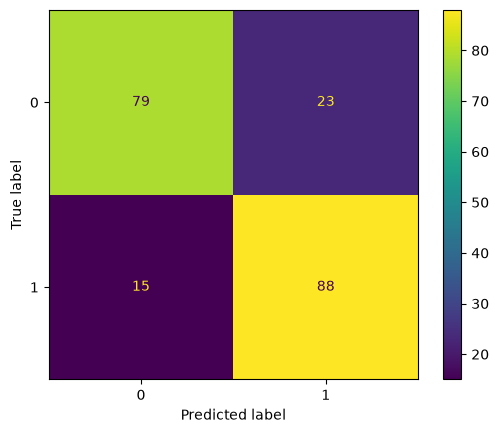

In [18]:
ConfusionMatrixDisplay(confusion_matrix = cm2).plot()
plt.show()

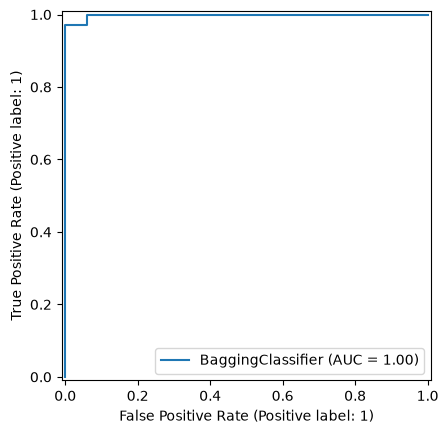

In [20]:
# ROC Curves

RocCurveDisplay.from_estimator(bag,x_test,y_test)
plt.show()

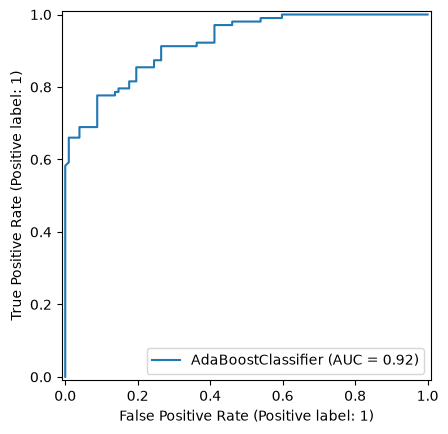

In [21]:
RocCurveDisplay.from_estimator(ada,x_test,y_test)
plt.show()

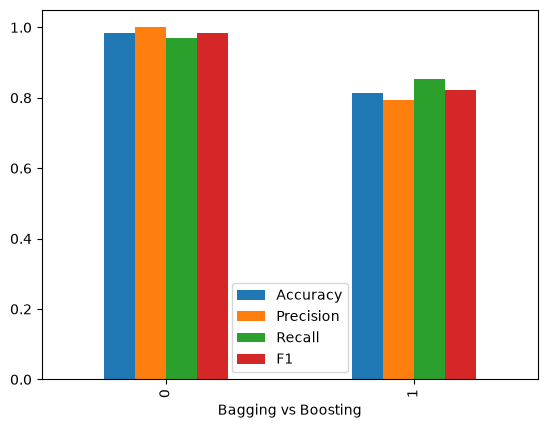

In [26]:
comparison.plot(kind = 'bar')
plt.xlabel("Bagging vs Boosting")
plt.show()

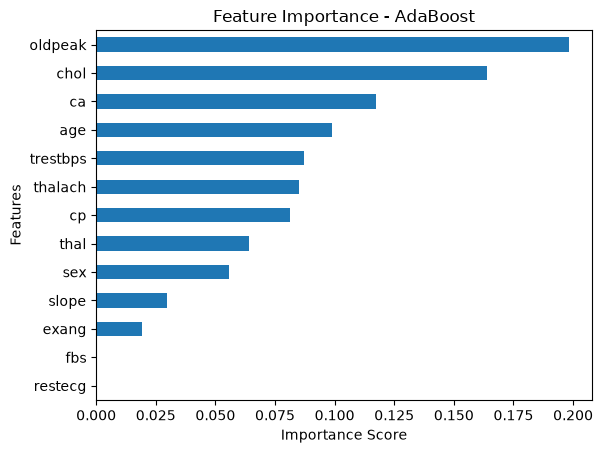

In [35]:
importance = pd.Series(ada.feature_importances_,index = x.columns)
importance = importance.sort_values()
importance.plot(kind = 'barh')
plt.title("Feature Importance - AdaBoost")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.show()

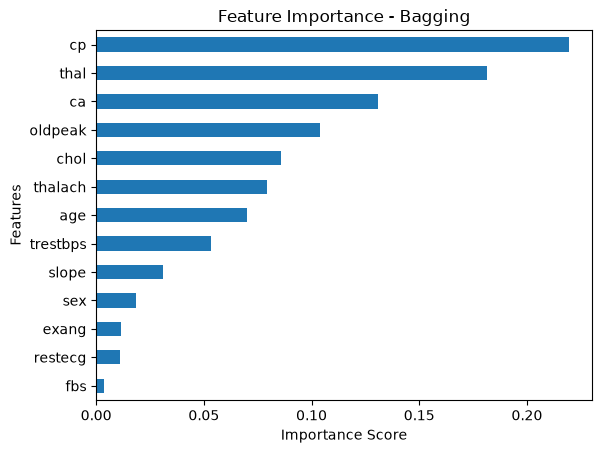

In [37]:
importance = np.mean(
    [tree.feature_importances_ for tree in bag.estimators_],
    axis=0
)

importance = pd.Series(
    importance,
    index=x.columns
)

importance = importance.sort_values()
importance.plot(kind = 'barh')
plt.title("Feature Importance - Bagging")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.show()
